In [2]:
import pandas as pd
import networkx as nx
import numpy as np

In [3]:
# 1. Load Data
edges_df = pd.read_csv("bluesky_large_edges_unweighted_10000 (1).csv")
metadata_df = pd.read_csv("ticker_metadata.csv").set_index('ticker')

# Build graph
G = nx.from_pandas_edgelist(edges_df, 'source', 'target')
nodes_count = G.number_of_nodes()
edges_count = G.number_of_edges()

In [4]:
# 2. Define structural hubs (top 5% degree)
degrees = dict(G.degree())
degree_threshold = np.percentile(list(degrees.values()), 95)
hubs = {node for node, deg in degrees.items() if deg >= degree_threshold}

In [5]:
# 3. Calculate betweenness centrality on GCC
components = sorted(nx.connected_components(G), key=len, reverse=True)
GCC = G.subgraph(components[0]).copy()

# Approximate betweenness centrality (k=500)
betweenness = nx.betweenness_centrality(GCC, k=500, seed=42)

# Create a master DataFrame for nodes
nodes_df = pd.DataFrame(index=list(G.nodes()))
nodes_df['degree'] = nodes_df.index.map(degrees)
nodes_df['is_hub'] = nodes_df.index.isin(hubs)
nodes_df['betweenness'] = nodes_df.index.map(betweenness).fillna(0)
nodes_df = nodes_df.join(metadata_df[['sector']])

summary = {
    "Graph Nodes": nodes_count,
    "Graph Edges": edges_count,
    "Degree Threshold (95th percentile)": degree_threshold,
    "Number of Hubs": len(hubs),
    "GCC Nodes": GCC.number_of_nodes()
}
print(summary)
nodes_df.sort_values('degree', ascending=False).head(10)

{'Graph Nodes': 6243, 'Graph Edges': 462904, 'Degree Threshold (95th percentile)': np.float64(606.0), 'Number of Hubs': 315, 'GCC Nodes': 6211}


,degree,is_hub,betweenness,sector
NVDA,1846,True,0.021355,Technology
SPY,1809,True,0.052735,NaN
TSLA,1619,True,0.017327,Consumer Cyclical
AAPL,1447,True,0.009012,Technology
QQQ,1425,True,0.031239,NaN
AMD,1389,True,0.007167,Technology
INTC,1365,True,0.005882,Technology
MU,1364,True,0.004812,Technology
AMZN,1357,True,0.006867,Consumer Cyclical
ORCL,1318,True,0.006659,Technology


From the initial data processing, we find:

- Network Construction: The simple, undirected, and unweighted graph contains 6,243 nodes and 462,904 edges.

- Structural Hubs (Top 5%): The 95th percentile for degree is 606. There are 315 tickers with a degree of 606 or higher. These constitute our structural hubs.

- Betweenness Centrality: The Giant Connected Component (GCC) contains 6,211 nodes. I calculated the approximate betweenness centrality on this GCC using a sample of 500 nodes (matching the methodology from your previous network characterization) to efficiently gauge how often these nodes act as bridges.

We now have a master dataset in memory containing each ticker's degree, hub status, betweenness centrality, and sector.

In [6]:
# Step 4 & 5: Sector Participation and Cross-Sector Edge Ratio
sector_map = metadata_df['sector'].to_dict()

participation = {}
known_neighbors_counts = {}
cross_sector_ratios = {}

for node in G.nodes():
    neighbors = list(G.neighbors(node))
    
    # Get sectors of neighbors, dropping NAs/Unknowns
    neighbor_sectors = [sector_map.get(n) for n in neighbors]
    valid_neighbor_sectors = [s for s in neighbor_sectors if pd.notna(s) and s != "Unknown"]
    
    ki = len(valid_neighbor_sectors)
    known_neighbors_counts[node] = ki
    
    # Only calculate detailed metrics if node has at least 5 known-sector neighbors
    if ki >= 5:
        # Calculate Participation Coefficient
        sector_counts = pd.Series(valid_neighbor_sectors).value_counts()
        p_i = 1.0 - sum((count / ki) ** 2 for count in sector_counts)
        participation[node] = p_i
        
        # Calculate cross-sector edge ratio (only if node itself has a known sector)
        node_sector = sector_map.get(node)
        if pd.notna(node_sector) and node_sector != "Unknown":
            same_sector_count = sector_counts.get(node_sector, 0)
            cross_sector_ratios[node] = 1.0 - (same_sector_count / ki)
        else:
            cross_sector_ratios[node] = np.nan
    else:
        participation[node] = np.nan
        cross_sector_ratios[node] = np.nan

nodes_df['known_sector_neighbors'] = nodes_df.index.map(known_neighbors_counts)
# Handle division by zero for isolated nodes (if any)
nodes_df['known_sector_neighbors_pct'] = np.where(nodes_df['degree'] > 0, 
                                                  nodes_df['known_sector_neighbors'] / nodes_df['degree'], 
                                                  0)
nodes_df['participation'] = nodes_df.index.map(participation)
nodes_df['cross_sector_ratio'] = nodes_df.index.map(cross_sector_ratios)

In [8]:
# Step 6: Narrative Bridge Score
# Compute Z-scores based on nodes that have valid participation scores
valid_nodes = nodes_df[nodes_df['participation'].notna()].copy()

mean_bw = valid_nodes['betweenness'].mean()
std_bw = valid_nodes['betweenness'].std()

mean_part = valid_nodes['participation'].mean()
std_part = valid_nodes['participation'].std()

valid_nodes['z_betweenness'] = (valid_nodes['betweenness'] - mean_bw) / std_bw
valid_nodes['z_participation'] = (valid_nodes['participation'] - mean_part) / std_part

# Composite Narrative Bridge Score
valid_nodes['bridge_score'] = valid_nodes['z_betweenness'] + valid_nodes['z_participation']

# Merge back to the main DataFrame
nodes_df['bridge_score'] = valid_nodes['bridge_score']

# Let's see the top narrative bridges
top_bridges = nodes_df.sort_values('bridge_score', ascending=False).head(15)
import tabulate
print(top_bridges[['sector', 'degree', 'betweenness', 'participation', 'cross_sector_ratio', 'bridge_score']].to_markdown())

|      | sector            |   degree |   betweenness |   participation |   cross_sector_ratio |   bridge_score |
|:-----|:------------------|---------:|--------------:|----------------:|---------------------:|---------------:|
| SPY  | nan               |     1809 |    0.0527349  |        0.85846  |           nan        |       47.4926  |
| QQQ  | nan               |     1425 |    0.0312393  |        0.850978 |           nan        |       28.1675  |
| NVDA | Technology        |     1846 |    0.0213547  |        0.87181  |             0.800842 |       19.5132  |
| TSLA | Consumer Cyclical |     1619 |    0.0173273  |        0.873338 |             0.87234  |       15.9206  |
| DIA  | nan               |     1046 |    0.0154642  |        0.842038 |           nan        |       13.9523  |
| AAPL | Technology        |     1447 |    0.00901166 |        0.878998 |             0.799541 |        8.52647 |
| MSFT | Technology        |     1274 |    0.00775173 |        0.87144  |             0.

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

# Step 7: Compare hubs and non-hubs
valid_hubs = nodes_df[(nodes_df['is_hub'] == True) & (nodes_df['participation'].notna())]
valid_non_hubs = nodes_df[(nodes_df['is_hub'] == False) & (nodes_df['participation'].notna())]

comparison_stats = pd.DataFrame({
    'Metric': ['Betweenness (Mean)', 'Betweenness (Median)', 'Participation (Mean)', 'Participation (Median)', 'Bridge Score (Mean)', 'Bridge Score (Median)'],
    'Hubs': [
        valid_hubs['betweenness'].mean(), valid_hubs['betweenness'].median(),
        valid_hubs['participation'].mean(), valid_hubs['participation'].median(),
        valid_hubs['bridge_score'].mean(), valid_hubs['bridge_score'].median()
    ],
    'Non-Hubs': [
        valid_non_hubs['betweenness'].mean(), valid_non_hubs['betweenness'].median(),
        valid_non_hubs['participation'].mean(), valid_non_hubs['participation'].median(),
        valid_non_hubs['bridge_score'].mean(), valid_non_hubs['bridge_score'].median()
    ]
})
print("--- Comparison: Hubs vs Non-Hubs ---")
print(comparison_stats.to_markdown(index=False))

--- Comparison: Hubs vs Non-Hubs ---
| Metric                 |       Hubs |     Non-Hubs |
|:-----------------------|-----------:|-------------:|
| Betweenness (Mean)     | 0.00217768 |  0.000152225 |
| Betweenness (Median)   | 0.00137621 |  3.9077e-05  |
| Participation (Mean)   | 0.865995   |  0.802048    |
| Participation (Median) | 0.866965   |  0.834506    |
| Bridge Score (Mean)    | 2.28087    | -0.145322    |
| Bridge Score (Median)  | 1.59366    |  0.115833    |


In [11]:
# Step 8: Sector-label permutation test
# We will permute the sector labels 100 times to create a null distribution of participation coefficients.
num_permutations = 100
empirical_participation = valid_nodes['participation'].mean()
empirical_hub_participation = valid_hubs['participation'].mean()

permuted_hub_participations = []
permuted_all_participations = []

# Array of valid sector labels to shuffle
sector_labels = nodes_df['sector'].values

np.random.seed(42)
for _ in range(num_permutations):
    shuffled_sectors = np.random.permutation(sector_labels)
    shuffled_map = dict(zip(nodes_df.index, shuffled_sectors))
    
    perm_participations = []
    perm_hub_participations = []
    
    for node in valid_nodes.index:
        neighbors = list(G.neighbors(node))
        # Get sectors of neighbors
        neighbor_sectors = [shuffled_map.get(n) for n in neighbors]
        valid_neighbor_sectors = [s for s in neighbor_sectors if pd.notna(s) and s != "Unknown"]
        
        ki = len(valid_neighbor_sectors)
        if ki >= 5:
            sector_counts = pd.Series(valid_neighbor_sectors).value_counts()
            p_i = 1.0 - sum((count / ki) ** 2 for count in sector_counts)
            perm_participations.append(p_i)
            if node in hubs:
                perm_hub_participations.append(p_i)
                
    permuted_all_participations.append(np.mean(perm_participations))
    permuted_hub_participations.append(np.mean(perm_hub_participations))

print("\n--- Permutation Test Results ---")
print(f"Empirical Hub Participation: {empirical_hub_participation:.4f}")
print(f"Permuted Hub Participation (Mean): {np.mean(permuted_hub_participations):.4f}")
print(f"Empirical All Nodes Participation: {empirical_participation:.4f}")
print(f"Permuted All Nodes Participation (Mean): {np.mean(permuted_all_participations):.4f}")


--- Permutation Test Results ---
Empirical Hub Participation: 0.8660
Permuted Hub Participation (Mean): 0.8705
Empirical All Nodes Participation: 0.8059
Permuted All Nodes Participation (Mean): 0.8466


C:\Users\abish\AppData\Local\Temp\ipykernel_9660\807145545.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


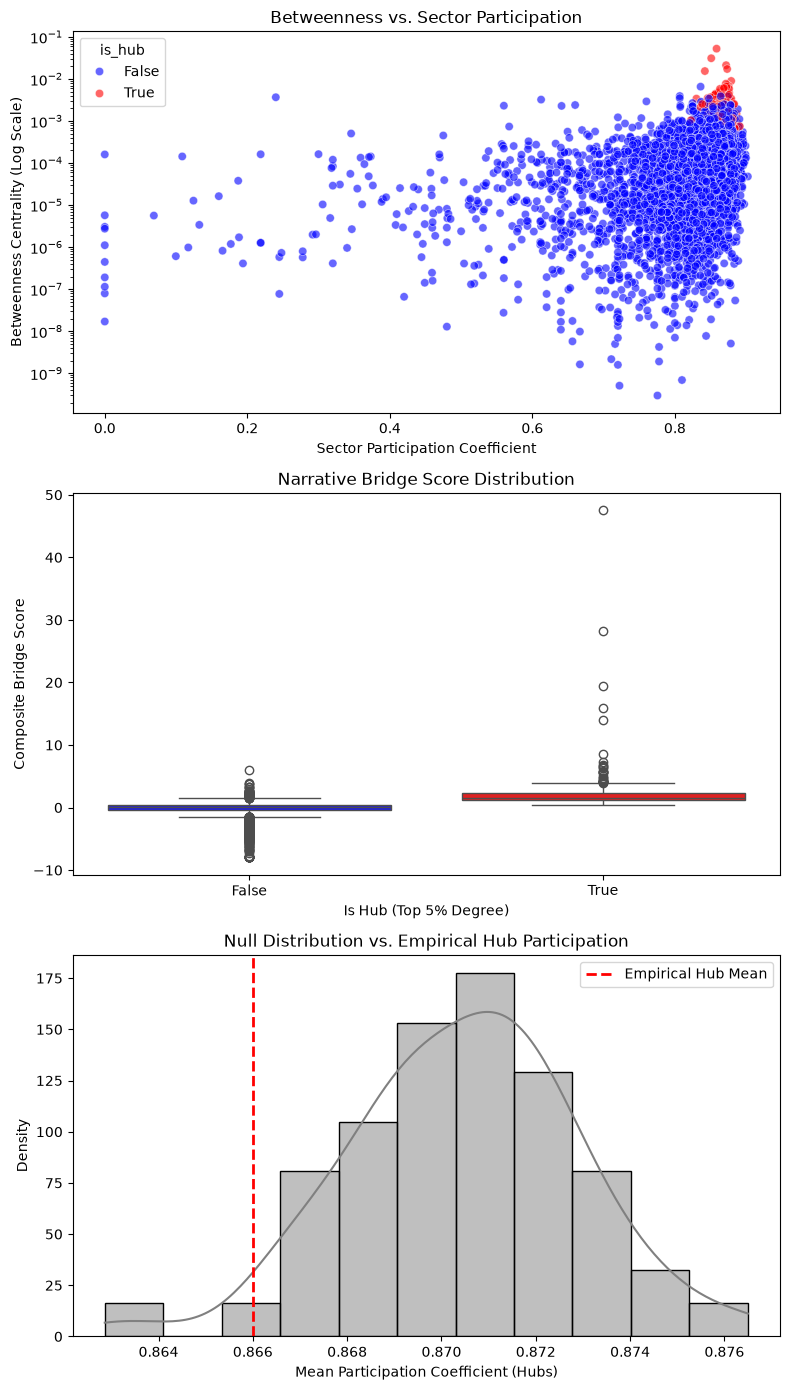

In [19]:
# Step 9: Visualizations
fig, axes = plt.subplots(3, 1, figsize=(8, 14))

# Plot 1: Scatter plot of Betweenness vs Participation
sns.scatterplot(
    data=valid_nodes, 
    x='participation', 
    y='betweenness', 
    hue='is_hub', 
    alpha=0.6, 
    ax=axes[0],
    palette={True: 'red', False: 'blue'}
)
axes[0].set_yscale('log') # using log scale as betweenness is highly skewed
axes[0].set_title('Betweenness vs. Sector Participation')
axes[0].set_xlabel('Sector Participation Coefficient')
axes[0].set_ylabel('Betweenness Centrality (Log Scale)')

# Plot 2: Boxplot comparing Bridge Score between Hubs and Non-Hubs
sns.boxplot(
    data=valid_nodes, 
    x='is_hub', 
    y='bridge_score', 
    ax=axes[1],
    palette={'True': 'red', 'False': 'blue'}
)
axes[1].set_title('Narrative Bridge Score Distribution')
axes[1].set_xlabel('Is Hub (Top 5% Degree)')
axes[1].set_ylabel('Composite Bridge Score')

# Plot 3: Histogram of Permutation Test (Hubs)
sns.histplot(permuted_hub_participations, kde=True, color='gray', ax=axes[2], stat='density')
axes[2].axvline(empirical_hub_participation, color='red', linestyle='dashed', linewidth=2, label='Empirical Hub Mean')
axes[2].set_title('Null Distribution vs. Empirical Hub Participation')
axes[2].set_xlabel('Mean Participation Coefficient (Hubs)')
axes[2].set_ylabel('Density')
axes[2].legend()

plt.tight_layout()
plt.savefig('bridge_analysis.png')
plt.show()